In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
print(torch.__version__)

2.11.0+cu128


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
torch.manual_seed(0)

In [4]:
!nvidia-smi

Sun Nov 22 00:37:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.66                 Driver Version: 591.66         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   39C    P8              1W /   40W |    1680MiB /   6141MiB |     45%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
train_df = pd.read_csv("../data/raw/mitbih_train.csv")
train_idx = np.load("../data/processed/train_idx.npy")
val_idx = np.load("../data/processed/val_idx.npy")

train_df.head()

,9.779411554336547852e-01,9.264705777168273926e-01,6.813725233078002930e-01,2.450980395078659058e-01,1.544117629528045654e-01,1.911764740943908691e-01,1.519607901573181152e-01,8.578431606292724609e-02,5.882352963089942932e-02,4.901960864663124084e-02,...,0.000000000000000000e+00.79,0.000000000000000000e+00.80,0.000000000000000000e+00.81,0.000000000000000000e+00.82,0.000000000000000000e+00.83,0.000000000000000000e+00.84,0.000000000000000000e+00.85,0.000000000000000000e+00.86,0.000000000000000000e+00.87,0.000000000000000000e+00.88
0,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.927461,1.000000,0.626943,0.193437,0.094991,0.072539,0.043178,0.053541,0.093264,0.189983,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
X = train_df.iloc[:,:-1]
y = train_df.iloc[:,-1]

In [7]:
train_X = X.iloc[train_idx]
val_X = X.iloc[val_idx]

train_y = y.iloc[train_idx]
val_y = y.iloc[val_idx]

In [8]:
print("Training shape:", train_X.shape)
print("Validation shape:", val_X.shape)

print("\nTraining class distribution:")
print(train_y.value_counts().sort_index())

print("\nValidation class distribution:")
print(val_y.value_counts().sort_index())

Training shape: (74420, 187)
Validation shape: (13133, 187)

Training class distribution:
0.000000000000000000e+00.88
0.0    61599
1.0     1890
2.0     4920
3.0      545
4.0     5466
Name: count, dtype: int64

Validation class distribution:
0.000000000000000000e+00.88
0.0    10871
1.0      333
2.0      868
3.0       96
4.0      965
Name: count, dtype: int64


In [9]:
train_features = train_X
train_labels = train_y

val_features = val_X
val_labels = val_y

In [10]:
train_features = torch.tensor(train_features.to_numpy(), dtype=torch.float32)
train_labels = torch.tensor(train_labels.to_numpy(), dtype=torch.long)

val_features = torch.tensor(val_features.to_numpy(), dtype=torch.float32)
val_labels = torch.tensor(val_labels.to_numpy(), dtype=torch.long)

In [11]:
class ECGDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        signal = self.features[idx]
        label = self.labels[idx]

        return signal, label

In [12]:
train_dataset = ECGDataset(train_features, train_labels)
val_dataset = ECGDataset(val_features, val_labels)

In [13]:
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))

print("Signal shape:", train_dataset[0][0].shape)
print("Label:", train_dataset[0][1])

Training: 74420
Validation: 13133
Signal shape: torch.Size([187])
Label: tensor(0)


In [14]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False,pin_memory=True)

In [15]:
class ECG_RNN(nn.Module):
    def __init__(self, cell="lstm", hidden=64, layers=2, dropout=0.2, n_classes=5):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(input_size=1, hidden_size=hidden, num_layers=layers,
                       batch_first=True, dropout=dropout, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden * 4, n_classes))

    def forward(self, x):                      # x: (B, 187)
        x = x.unsqueeze(-1)                    # (B, 187, 1)
        out, _ = self.rnn(x)                   # (B, 187, 2*hidden)
        feat = torch.cat([out.mean(dim=1), out.max(dim=1).values], dim=1)
        return self.head(feat)

In [16]:
# lstm_model = ECG_RNN(cell='lstm').to(device)
# gru_model = ECG_RNN(cell='gru').to(device)

In [17]:
classes = np.unique(train_y)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_y
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print(class_weights)

tensor([ 0.2416,  7.8751,  3.0252, 27.3101,  2.7230], device='cuda:0')


In [19]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

lstm_plain_model = ECG_RNN(cell='lstm').to(device)
criterion_lstm_plain = nn.CrossEntropyLoss()
optimizer_lstm_plain = optim.Adam(lstm_plain_model.parameters(), lr=learning_rate)

history_plain_lstm = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    lstm_plain_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_lstm_plain.zero_grad()

        outputs = lstm_plain_model(features)

        loss = criterion_lstm_plain(outputs, labels)

        loss.backward()

        optimizer_lstm_plain.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    lstm_plain_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = lstm_plain_model(features)

            loss = criterion_lstm_plain(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_plain_lstm["epoch"].append(epoch + 1)
    history_plain_lstm["train_loss"].append(avg_train_loss)
    history_plain_lstm["val_loss"].append(avg_val_loss)
    history_plain_lstm["accuracy"].append(accuracy)
    history_plain_lstm["balanced_accuracy"].append(balanced_acc)
    history_plain_lstm["precision"].append(precision)
    history_plain_lstm["recall"].append(recall)
    history_plain_lstm["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            lstm_plain_model.state_dict(),
            "../models/lstm_plain.pt"
        )

        print("Best LSTM PLAIN model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best LSTM PLAIN model saved!
Epoch [1/50] Train Loss: 0.3691 | Val Loss: 0.2093 | Accuracy: 0.9421 | Balanced Acc: 0.5443 | Macro F1: 0.5777
Best LSTM PLAIN model saved!
Epoch [2/50] Train Loss: 0.1999 | Val Loss: 0.1853 | Accuracy: 0.9478 | Balanced Acc: 0.5673 | Macro F1: 0.5925
Best LSTM PLAIN model saved!
Epoch [3/50] Train Loss: 0.1576 | Val Loss: 0.1174 | Accuracy: 0.9697 | Balanced Acc: 0.7746 | Macro F1: 0.8328
Epoch [4/50] Train Loss: 0.1403 | Val Loss: 0.1083 | Accuracy: 0.9689 | Balanced Acc: 0.7709 | Macro F1: 0.8262
Best LSTM PLAIN model saved!
Epoch [5/50] Train Loss: 0.1203 | Val Loss: 0.0913 | Accuracy: 0.9756 | Balanced Acc: 0.8262 | Macro F1: 0.8666
Best LSTM PLAIN model saved!
Epoch [6/50] Train Loss: 0.1104 | Val Loss: 0.0813 | Accuracy: 0.9777 | Balanced Acc: 0.8249 | Macro F1: 0.8687
Best LSTM PLAIN model saved!
Epoch [7/50] Train Loss: 0.1015 | Val Loss: 0.0826 | Accuracy: 0.9773 | Balanced Acc: 0.8183 | Macro F1: 0.8717
Best LSTM PLAIN model saved!
Epoch [8/50] 

In [20]:
history_plain_lstm_df = pd.DataFrame(history_plain_lstm)

history_plain_lstm_df.to_csv(
    "../results/metrics/lstm_plain_history.csv",
    index=False
)

In [21]:
lstm_plain_model.load_state_dict(
    torch.load(
        "../models/lstm_plain.pt",
        map_location=device,
        weights_only=True
    )
)

lstm_plain_model.eval()

print("Best LSTM PLAIN model loaded successfully!")

Best LSTM PLAIN model loaded successfully!


In [22]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = lstm_plain_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [23]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/lstm_plain_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.990137,0.997332,0.993722,10871.000000
Supraventricular,0.943463,0.801802,0.866883,333.000000
Ventricular,0.978972,0.965438,0.972158,868.000000
Fusion,0.861702,0.843750,0.852632,96.000000
Unknown,0.997895,0.982383,0.990078,965.000000
accuracy,0.988045,0.988045,0.988045,0.988045
macro avg,0.954434,0.918141,0.935094,13133.000000
weighted avg,0.987847,0.988045,0.987781,13133.000000


In [24]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/lstm_plain_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10842,15,7,5,2
Supraventricular,64,267,2,0,0
Ventricular,21,1,838,8,0
Fusion,8,0,7,81,0
Unknown,15,0,2,0,948


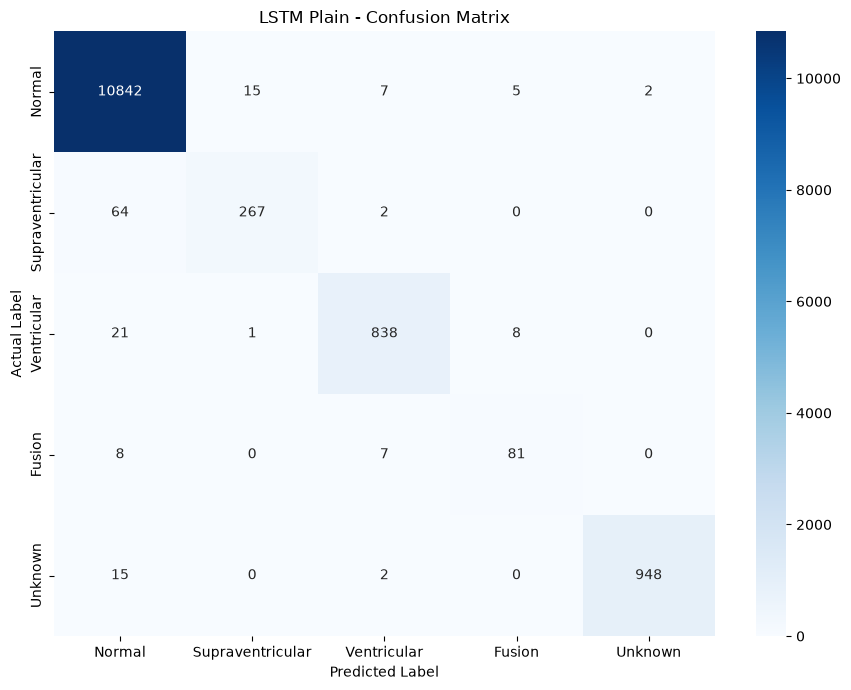

In [25]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Plain - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_plain_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

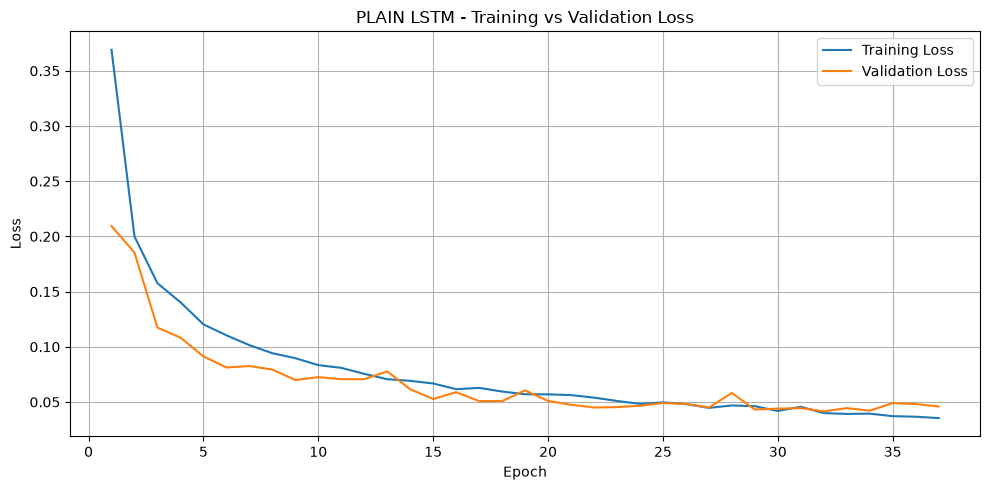

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_plain_lstm_df["epoch"],
    history_plain_lstm_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_plain_lstm_df["epoch"],
    history_plain_lstm_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PLAIN LSTM - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_plain_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

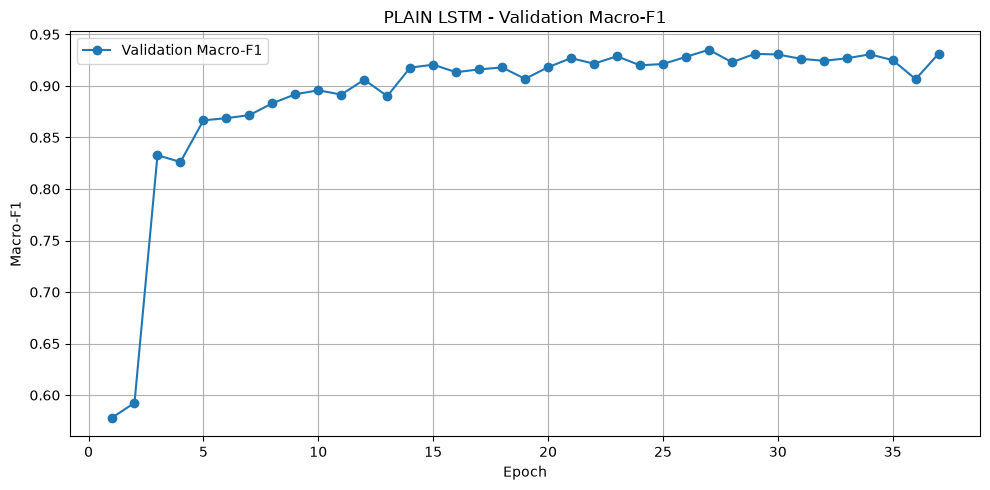

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_plain_lstm_df["epoch"],
    history_plain_lstm_df["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("PLAIN LSTM - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_plain_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

lstm_weighted_model = ECG_RNN(cell='lstm').to(device)
criterion_lstm_weighted = nn.CrossEntropyLoss(weight=class_weights)
optimizer_lstm_weighted = optim.Adam(lstm_weighted_model.parameters(), lr=learning_rate)

history_weighted_lstm = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    lstm_weighted_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_lstm_weighted.zero_grad()

        outputs = lstm_weighted_model(features)

        loss = criterion_lstm_weighted(outputs, labels)

        loss.backward()

        optimizer_lstm_weighted.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    lstm_weighted_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = lstm_weighted_model(features)

            loss = criterion_lstm_weighted(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_weighted_lstm["epoch"].append(epoch + 1)
    history_weighted_lstm["train_loss"].append(avg_train_loss)
    history_weighted_lstm["val_loss"].append(avg_val_loss)
    history_weighted_lstm["accuracy"].append(accuracy)
    history_weighted_lstm["balanced_accuracy"].append(balanced_acc)
    history_weighted_lstm["precision"].append(precision)
    history_weighted_lstm["recall"].append(recall)
    history_weighted_lstm["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            lstm_weighted_model.state_dict(),
            "../models/lstm_weighted.pt"
        )

        print("Best WEIGHTED LSTM model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best WEIGHTED LSTM model saved!
Epoch [1/50] Train Loss: 1.1376 | Val Loss: 0.6227 | Accuracy: 0.8417 | Balanced Acc: 0.7579 | Macro F1: 0.6103
Epoch [2/50] Train Loss: 0.6005 | Val Loss: 0.4916 | Accuracy: 0.7139 | Balanced Acc: 0.8363 | Macro F1: 0.5511
Epoch [3/50] Train Loss: 0.5062 | Val Loss: 0.4412 | Accuracy: 0.7990 | Balanced Acc: 0.8367 | Macro F1: 0.6011
Best WEIGHTED LSTM model saved!
Epoch [4/50] Train Loss: 0.4442 | Val Loss: 0.3606 | Accuracy: 0.9022 | Balanced Acc: 0.8687 | Macro F1: 0.6996
Best WEIGHTED LSTM model saved!
Epoch [5/50] Train Loss: 0.3980 | Val Loss: 0.3330 | Accuracy: 0.9328 | Balanced Acc: 0.8711 | Macro F1: 0.7469
Epoch [6/50] Train Loss: 0.3829 | Val Loss: 0.3292 | Accuracy: 0.9011 | Balanced Acc: 0.8822 | Macro F1: 0.7004
Epoch [7/50] Train Loss: 0.3602 | Val Loss: 0.2973 | Accuracy: 0.8663 | Balanced Acc: 0.8956 | Macro F1: 0.6903
Epoch [8/50] Train Loss: 0.3306 | Val Loss: 0.2942 | Accuracy: 0.9092 | Balanced Acc: 0.8925 | Macro F1: 0.7219
Best WEI

In [29]:
history_lstm_weighted_df = pd.DataFrame(history_weighted_lstm)

history_lstm_weighted_df.to_csv(
    "../results/metrics/lstm_weighted_history.csv",
    index=False
)

In [30]:
lstm_weighted_model.load_state_dict(
    torch.load(
        "../models/lstm_weighted.pt",
        map_location=device,
        weights_only=True
    )
)

lstm_weighted_model.eval()

print("Best LSTM WEIGHTED model loaded successfully!")

Best LSTM WEIGHTED model loaded successfully!


In [31]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = lstm_weighted_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [32]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/lstm_weighted_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.995830,0.966608,0.981002,10871.000000
Supraventricular,0.609053,0.888889,0.722833,333.000000
Ventricular,0.879707,0.968894,0.922149,868.000000
Fusion,0.587838,0.906250,0.713115,96.000000
Unknown,0.965691,0.991710,0.978528,965.000000
accuracy,0.966192,0.966192,0.966192,0.966192
macro avg,0.807624,0.944470,0.863525,13133.000000
weighted avg,0.973151,0.966192,0.968426,13133.000000


In [33]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/lstm_weighted_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10508,190,97,44,32
Supraventricular,28,296,8,1,0
Ventricular,9,0,841,16,2
Fusion,4,0,5,87,0
Unknown,3,0,5,0,957


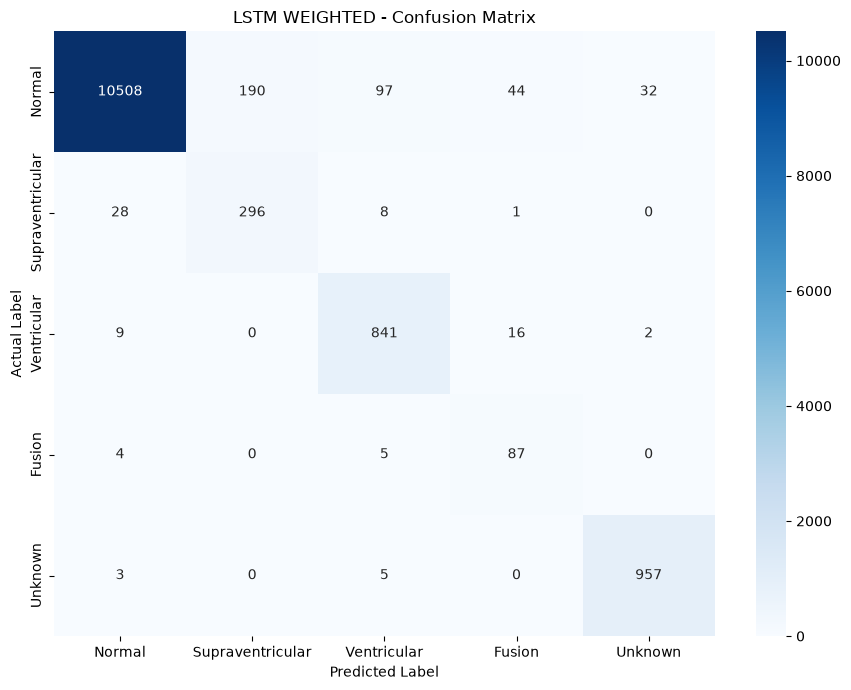

In [34]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM WEIGHTED - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_weighted_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

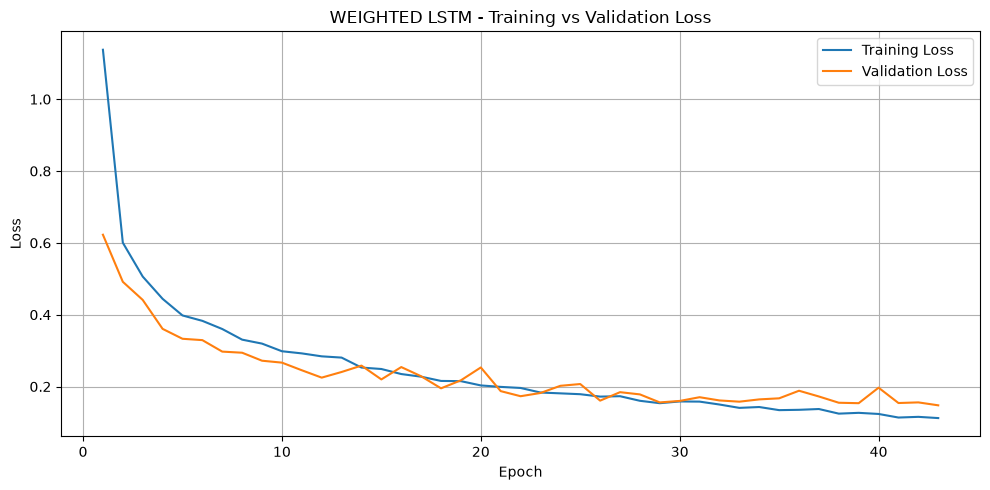

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm_weighted_df["epoch"],
    history_lstm_weighted_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm_weighted_df["epoch"],
    history_lstm_weighted_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("WEIGHTED LSTM - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_weighted_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

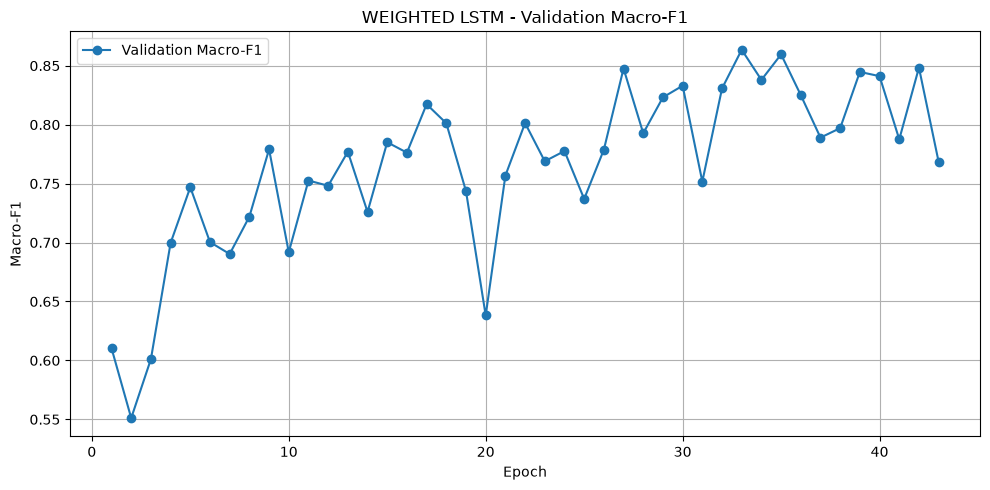

In [36]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_weighted_lstm["epoch"],
    history_weighted_lstm["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("WEIGHTED LSTM - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_weighted_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

gru_plain_model = ECG_RNN(cell='gru').to(device)
criterion_gru_plain = nn.CrossEntropyLoss()
optimizer_gru_plain = optim.Adam(gru_plain_model.parameters(), lr=learning_rate)

history_gru_plain = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    gru_plain_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_gru_plain.zero_grad()

        outputs = gru_plain_model(features)

        loss = criterion_gru_plain(outputs, labels)

        loss.backward()

        optimizer_gru_plain.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    gru_plain_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = gru_plain_model(features)

            loss = criterion_gru_plain(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_gru_plain["epoch"].append(epoch + 1)
    history_gru_plain["train_loss"].append(avg_train_loss)
    history_gru_plain["val_loss"].append(avg_val_loss)
    history_gru_plain["accuracy"].append(accuracy)
    history_gru_plain["balanced_accuracy"].append(balanced_acc)
    history_gru_plain["precision"].append(precision)
    history_gru_plain["recall"].append(recall)
    history_gru_plain["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            gru_plain_model.state_dict(),
            "../models/gru_plain.pt"
        )

        print("Best GRU PLAIN model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best GRU PLAIN model saved!
Epoch [1/50] Train Loss: 0.3283 | Val Loss: 0.1664 | Accuracy: 0.9578 | Balanced Acc: 0.6947 | Macro F1: 0.7545
Best GRU PLAIN model saved!
Epoch [2/50] Train Loss: 0.1573 | Val Loss: 0.1156 | Accuracy: 0.9690 | Balanced Acc: 0.7762 | Macro F1: 0.8394
Epoch [3/50] Train Loss: 0.1242 | Val Loss: 0.1122 | Accuracy: 0.9666 | Balanced Acc: 0.7605 | Macro F1: 0.8099
Best GRU PLAIN model saved!
Epoch [4/50] Train Loss: 0.1067 | Val Loss: 0.0880 | Accuracy: 0.9747 | Balanced Acc: 0.7954 | Macro F1: 0.8542
Best GRU PLAIN model saved!
Epoch [5/50] Train Loss: 0.0944 | Val Loss: 0.0779 | Accuracy: 0.9772 | Balanced Acc: 0.8509 | Macro F1: 0.8818
Best GRU PLAIN model saved!
Epoch [6/50] Train Loss: 0.0850 | Val Loss: 0.0724 | Accuracy: 0.9802 | Balanced Acc: 0.8621 | Macro F1: 0.8882
Best GRU PLAIN model saved!
Epoch [7/50] Train Loss: 0.0783 | Val Loss: 0.0624 | Accuracy: 0.9833 | Balanced Acc: 0.8833 | Macro F1: 0.9080
Epoch [8/50] Train Loss: 0.0726 | Val Loss: 0.06

In [39]:
history_gru_plain_df = pd.DataFrame(history_gru_plain)

history_gru_plain_df.to_csv(
    "../results/metrics/gru_plain_history.csv",
    index=False
)

In [40]:
gru_plain_model.load_state_dict(
    torch.load(
        "../models/gru_plain.pt",
        map_location=device,
        weights_only=True
    )
)

gru_plain_model.eval()

print("Best PLAIN GRU model loaded successfully!")

Best PLAIN GRU model loaded successfully!


In [41]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = gru_plain_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [42]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/gru_plain_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.991585,0.997240,0.994405,10871.000000
Supraventricular,0.948097,0.822823,0.881029,333.000000
Ventricular,0.964733,0.976959,0.970807,868.000000
Fusion,0.946667,0.739583,0.830409,96.000000
Unknown,0.995820,0.987565,0.991675,965.000000
accuracy,0.988883,0.988883,0.988883,0.988883
macro avg,0.969380,0.904834,0.933665,13133.000000
weighted avg,0.988691,0.988883,0.988571,13133.000000


In [43]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/gru_plain_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10841,15,10,2,3
Supraventricular,55,274,3,0,1
Ventricular,18,0,848,2,0
Fusion,9,0,16,71,0
Unknown,10,0,2,0,953


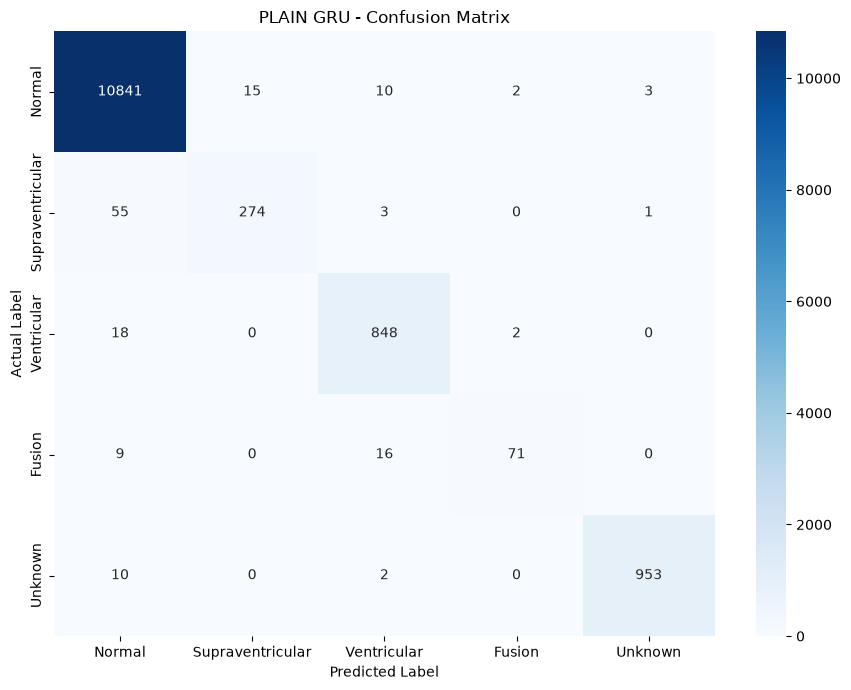

In [44]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("PLAIN GRU - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_plain_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

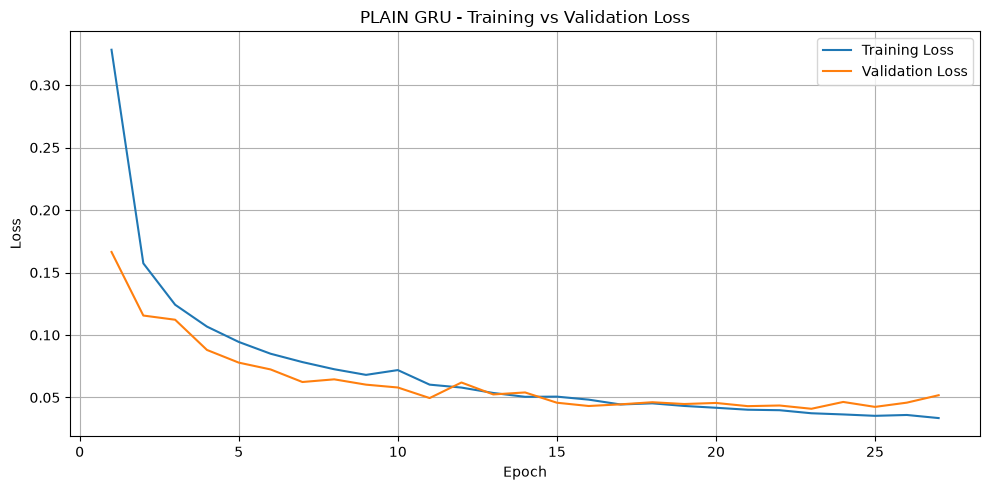

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_plain["epoch"],
    history_gru_plain["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_gru_plain["epoch"],
    history_gru_plain["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PLAIN GRU - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_plain_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

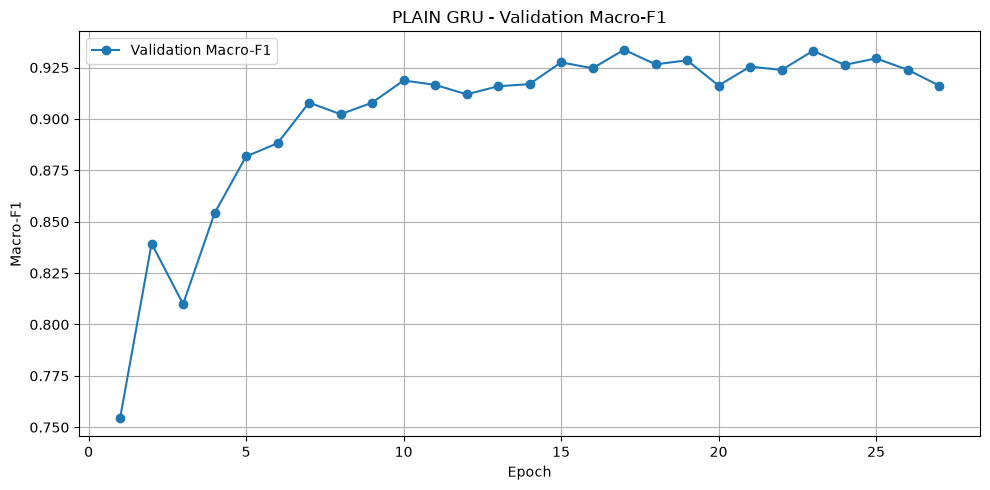

In [57]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_plain["epoch"],
    history_gru_plain["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("PLAIN GRU - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/plain_gru_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

gru_weighted_model = ECG_RNN(cell='gru').to(device)
criterion_gru_weighted = nn.CrossEntropyLoss(weight=class_weights)
optimizer_gru_weighted = optim.Adam(gru_weighted_model.parameters(), lr=learning_rate)

history_gru_weighted = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    gru_weighted_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_gru_weighted.zero_grad()

        outputs = gru_weighted_model(features)

        loss = criterion_gru_weighted(outputs, labels)

        loss.backward()

        optimizer_gru_weighted.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    gru_plain_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = gru_weighted_model(features)

            loss = criterion_gru_weighted(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_gru_weighted["epoch"].append(epoch + 1)
    history_gru_weighted["train_loss"].append(avg_train_loss)
    history_gru_weighted["val_loss"].append(avg_val_loss)
    history_gru_weighted["accuracy"].append(accuracy)
    history_gru_weighted["balanced_accuracy"].append(balanced_acc)
    history_gru_weighted["precision"].append(precision)
    history_gru_weighted["recall"].append(recall)
    history_gru_weighted["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            gru_plain_model.state_dict(),
            "../models/gru_weighted.pt"
        )

        print("Best GRU WEIGHTED model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best GRU WEIGHTED model saved!
Epoch [1/50] Train Loss: 0.9609 | Val Loss: 0.6331 | Accuracy: 0.6340 | Balanced Acc: 0.7649 | Macro F1: 0.4849
Best GRU WEIGHTED model saved!
Epoch [2/50] Train Loss: 0.5395 | Val Loss: 0.4563 | Accuracy: 0.8138 | Balanced Acc: 0.8355 | Macro F1: 0.6213
Best GRU WEIGHTED model saved!
Epoch [3/50] Train Loss: 0.4470 | Val Loss: 0.3701 | Accuracy: 0.8358 | Balanced Acc: 0.8630 | Macro F1: 0.6614
Epoch [4/50] Train Loss: 0.3795 | Val Loss: 0.3503 | Accuracy: 0.8606 | Balanced Acc: 0.8714 | Macro F1: 0.6484
Epoch [5/50] Train Loss: 0.3502 | Val Loss: 0.3039 | Accuracy: 0.8629 | Balanced Acc: 0.8867 | Macro F1: 0.6565
Best GRU WEIGHTED model saved!
Epoch [6/50] Train Loss: 0.3159 | Val Loss: 0.2908 | Accuracy: 0.8880 | Balanced Acc: 0.8949 | Macro F1: 0.7029
Epoch [7/50] Train Loss: 0.2905 | Val Loss: 0.2988 | Accuracy: 0.8192 | Balanced Acc: 0.8866 | Macro F1: 0.6739
Best GRU WEIGHTED model saved!
Epoch [8/50] Train Loss: 0.2708 | Val Loss: 0.2685 | Accuracy

In [48]:
history_gru_weighted_df = pd.DataFrame(history_gru_weighted)

history_gru_weighted_df.to_csv(
    "../results/metrics/gru_weighted_history.csv",
    index=False
)

In [49]:
gru_weighted_model.load_state_dict(
    torch.load(
        "../models/gru_weighted.pt",
        map_location=device,
        weights_only=True
    )
)

gru_weighted_model.eval()

print("Best WEIGHTED GRU model loaded successfully!")

Best WEIGHTED GRU model loaded successfully!


In [50]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = gru_weighted_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [51]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/gru_weighted_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.991585,0.997240,0.994405,10871.000000
Supraventricular,0.948097,0.822823,0.881029,333.000000
Ventricular,0.964733,0.976959,0.970807,868.000000
Fusion,0.946667,0.739583,0.830409,96.000000
Unknown,0.995820,0.987565,0.991675,965.000000
accuracy,0.988883,0.988883,0.988883,0.988883
macro avg,0.969380,0.904834,0.933665,13133.000000
weighted avg,0.988691,0.988883,0.988571,13133.000000


In [52]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/gru_weighted_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10841,15,10,2,3
Supraventricular,55,274,3,0,1
Ventricular,18,0,848,2,0
Fusion,9,0,16,71,0
Unknown,10,0,2,0,953


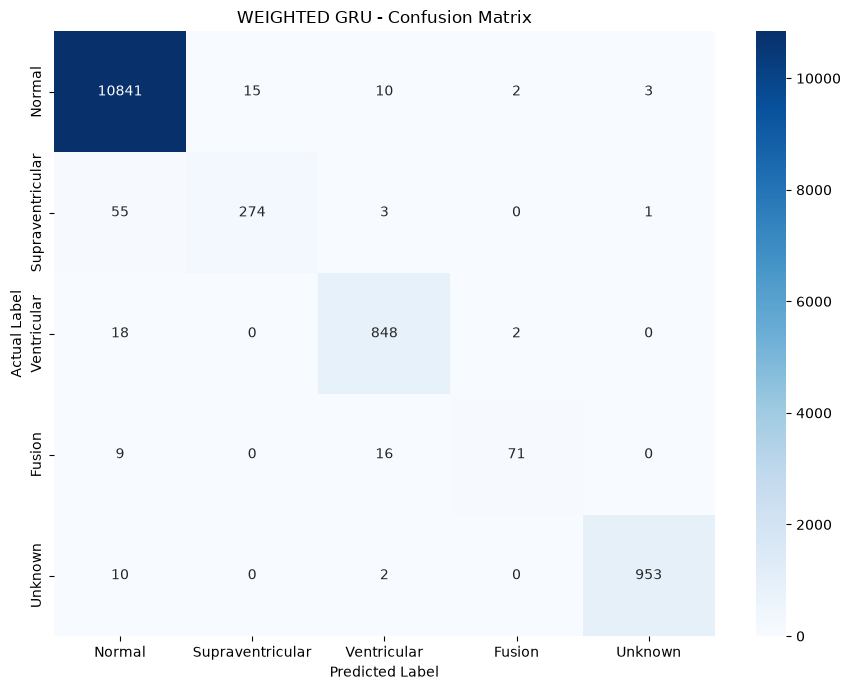

In [53]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("WEIGHTED GRU - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_weighted_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

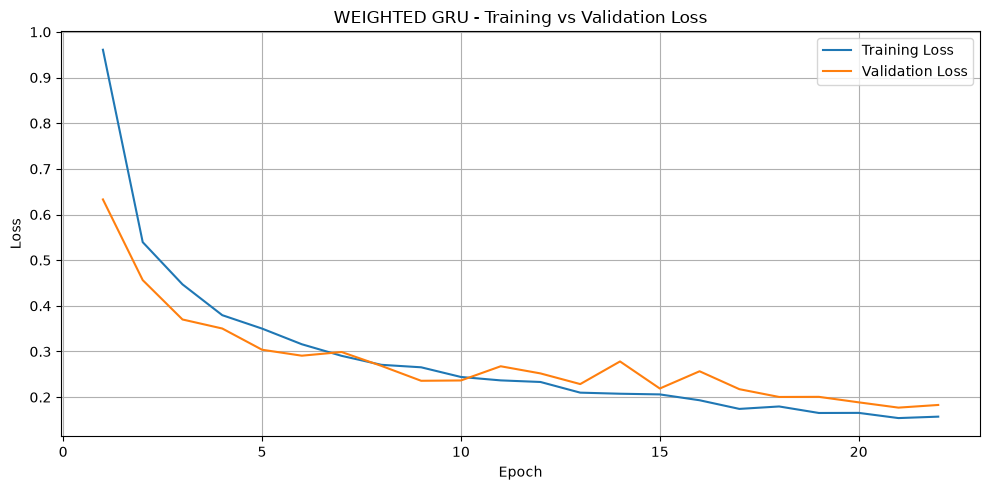

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_weighted["epoch"],
    history_gru_weighted["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_gru_weighted["epoch"],
    history_gru_weighted["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("WEIGHTED GRU - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_weighted_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

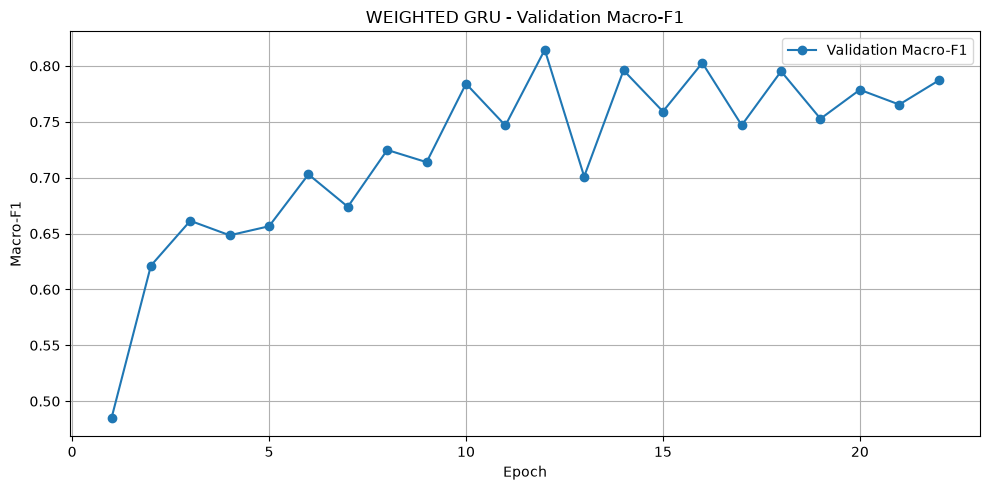

In [55]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_weighted["epoch"],
    history_gru_weighted["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("WEIGHTED GRU - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/weighted_gru_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()